# Volatility Trading: Variance Swaps and the Volatility Risk Premium

On an equity derivatives desk, volatility is an asset class of its own. The cleanest way to
trade it is the **variance swap**: at maturity, it pays the difference between the variance
actually realised by the index and a strike fixed today. No delta hedging, no path dependency
on the strike, just volatility.

This notebook covers:

1. **Pricing**: the fair strike is a strip of out-of-the-money options weighted by $1/K^2$, so
   the skew makes variance more expensive than at-the-money volatility.
2. **Payoff**: why variance is convex in volatility, and how traders size it in vega notional.
3. **The volatility risk premium**: implied volatility tends to exceed the volatility later
   realised. Selling it pays most months, and costs a lot in a crash.

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("voltrading.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/27-volatility-trading")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from voltrading import (skew_smile, variance_swap_strike, realised_variance, variance_swap_pnl, simulate_market,
                        short_variance_strategy, short_straddle_hedged)

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL, GOLD = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f", "#b08d3c"

## 1. Pricing a variance swap by replication

Demeterfi, Derman, Kamal and Zou (1999) show that a log contract, which a portfolio of options
replicates, delivers realised variance. The fair strike is

$$K_{var} = \frac{2e^{rT}}{T}\left(\int_0^F \frac{P(K)}{K^2}\,dK + \int_F^\infty \frac{C(K)}{K^2}\,dK\right)$$

Low strikes carry the most weight ($1/K^2$), and with an equity skew those puts are expensive.

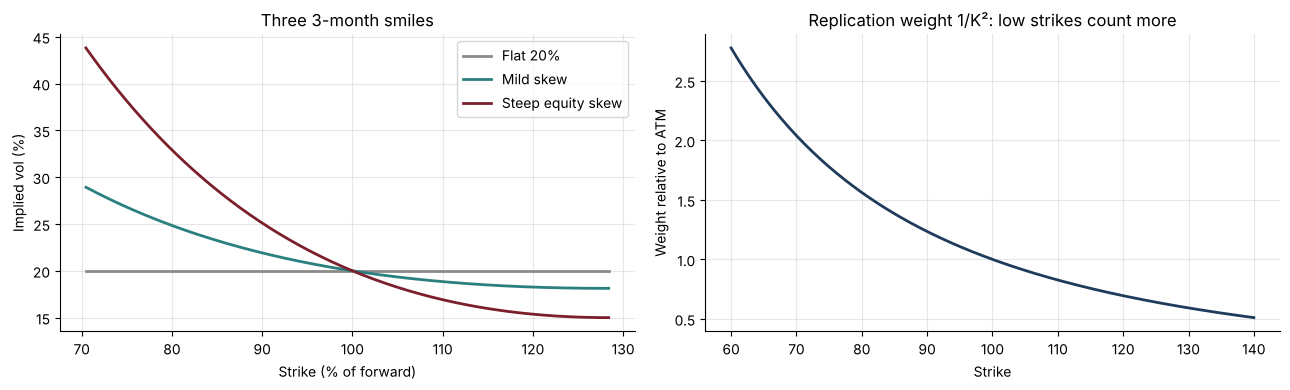

,ATM vol,Variance swap strike (vol)
Smile,,
Flat 20%,20.00%,20.00%
Mild skew,20.00%,20.66%
Steep equity skew,20.00%,23.52%


In [2]:
S, r, T = 100.0, 0.03, 0.25
smiles = {"Flat 20%": lambda k: np.full_like(k, 0.20), "Mild skew": skew_smile(0.20, -0.15, 0.3),
          "Steep equity skew": skew_smile(0.20, -0.40, 0.8)}
k = np.linspace(-0.35, 0.25, 200)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
rows = []
for (name, sm), c in zip(smiles.items(), [GREY, TEAL, BORDEAUX]):
    axes[0].plot(np.exp(k) * 100, sm(k) * 100, color=c, lw=2, label=name)
    kv = variance_swap_strike(S, T, r, sm)
    rows.append({"Smile": name, "ATM vol": sm(np.array([0.0]))[0], "Variance swap strike (vol)": np.sqrt(kv)})
axes[0].set(xlabel="Strike (% of forward)", ylabel="Implied vol (%)", title="Three 3-month smiles"); axes[0].legend()
strikes = np.linspace(60, 140, 200)
axes[1].plot(strikes, 1 / strikes**2 / (1 / 100**2), color=NAVY, lw=2)
axes[1].set(xlabel="Strike", ylabel="Weight relative to ATM", title="Replication weight 1/K²: low strikes count more")
plt.tight_layout(); plt.savefig("images/replication.png", dpi=150); plt.show()
pd.DataFrame(rows).set_index("Smile").style.format("{:.2%}")

With a flat smile, replication returns exactly the 20% volatility (a test checks it). With an
equity skew, the variance strike sits well above the at-the-money vol: the buyer of variance pays for
the crash protection embedded in the low-strike puts.

## 2. The payoff: convex in volatility

A variance swap pays $N_{var}(\sigma_R^2 - K^2)$. Traders size it in **vega notional**, the P&L
for a one-point move in volatility near the strike: $N_{var} = N_{vega}/(2K)$. Because the
payoff is in variance, a long position gains more when volatility rises than it loses
when volatility falls by the same amount.

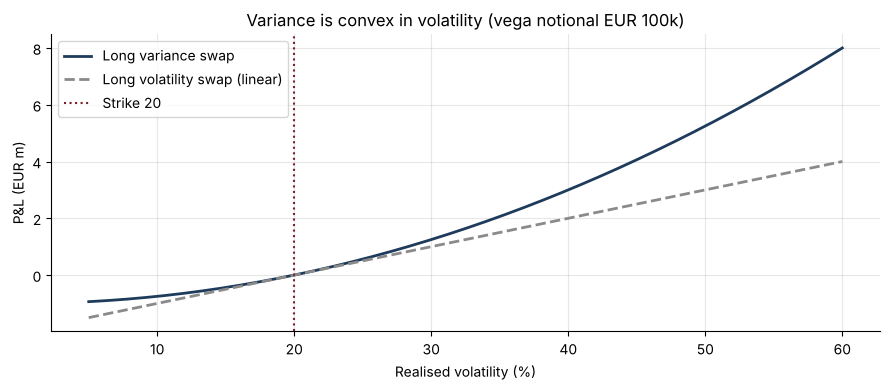

Realised 30 vs strike 20: 1,250,000;   realised 10: -750,000


In [3]:
vols = np.linspace(5, 60, 200)
K, vega = 20.0, 100_000
var_pnl = variance_swap_pnl((vols / 100) ** 2, (K / 100) ** 2, vega)
vol_pnl = vega * (vols - K)
plt.figure(figsize=(9, 4))
plt.plot(vols, var_pnl / 1e6, color=NAVY, lw=2, label="Long variance swap")
plt.plot(vols, vol_pnl / 1e6, color=GREY, lw=2, ls="--", label="Long volatility swap (linear)")
plt.axvline(K, color=BORDEAUX, ls=":", label="Strike 20")
plt.xlabel("Realised volatility (%)"); plt.ylabel("P&L (EUR m)"); plt.legend()
plt.title("Variance is convex in volatility (vega notional EUR 100k)")
plt.tight_layout(); plt.savefig("images/convexity.png", dpi=150); plt.show()
print(f"Realised 30 vs strike 20: {variance_swap_pnl(0.09, 0.04, vega):,.0f};   realised 10: {variance_swap_pnl(0.01, 0.04, vega):,.0f}")

For the **seller**, this convexity is the danger: on a €100k vega notional, a jump in realised
volatility from 20 to 60 costs €8m, more than ten times what a fall to 10 would earn (€0.75m).

## 3. The volatility risk premium

Fifteen years of a simulated index with stochastic volatility and occasional crashes. Each day
the market quotes a one-month implied volatility equal to the expected volatility plus a
premium, which is what investors pay for protection.

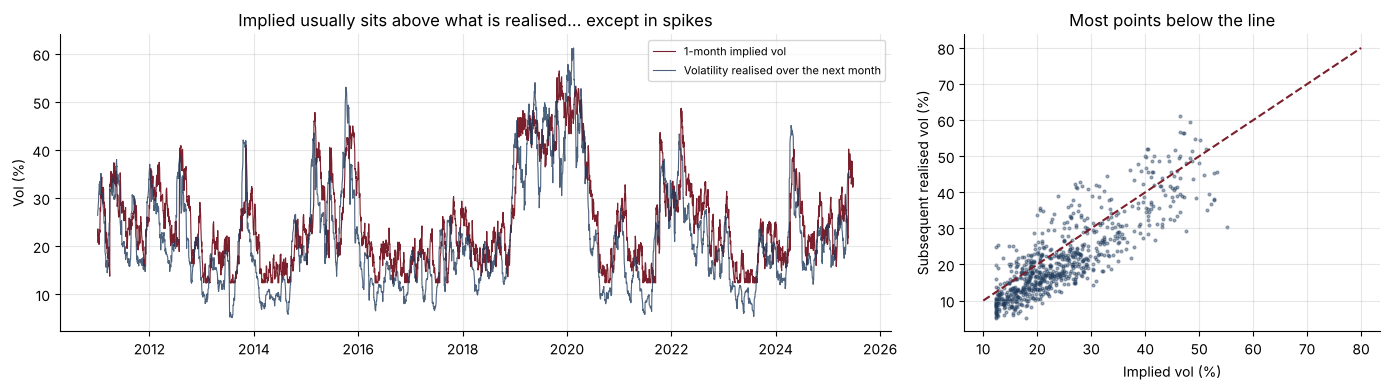

Share of days where implied > subsequent realised: 76%


In [4]:
prices, true_vol, implied = simulate_market(15, seed=3)
days = pd.bdate_range("2011-01-03", periods=len(prices))
rv_fwd = pd.Series(np.log(prices)).diff().pow(2).rolling(21).mean().shift(-21).mul(252).pow(0.5).values
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(days, implied * 100, color=BORDEAUX, lw=0.8, label="1-month implied vol")
axes[0].plot(days, rv_fwd * 100, color=NAVY, lw=0.8, alpha=0.8, label="Volatility realised over the next month")
axes[0].set(ylabel="Vol (%)", title="Implied usually sits above what is realised... except in spikes"); axes[0].legend(fontsize=8)
m = ~np.isnan(rv_fwd)
axes[1].scatter(implied[m][::5] * 100, rv_fwd[m][::5] * 100, s=4, alpha=0.4, color=NAVY)
axes[1].plot([10, 80], [10, 80], color=BORDEAUX, ls="--")
axes[1].set(xlabel="Implied vol (%)", ylabel="Subsequent realised vol (%)", title="Most points below the line")
plt.tight_layout(); plt.savefig("images/vrp.png", dpi=150); plt.show()
print(f"Share of days where implied > subsequent realised: {(implied[m] > rv_fwd[m]).mean():.0%}")

## 4. Selling variance every month

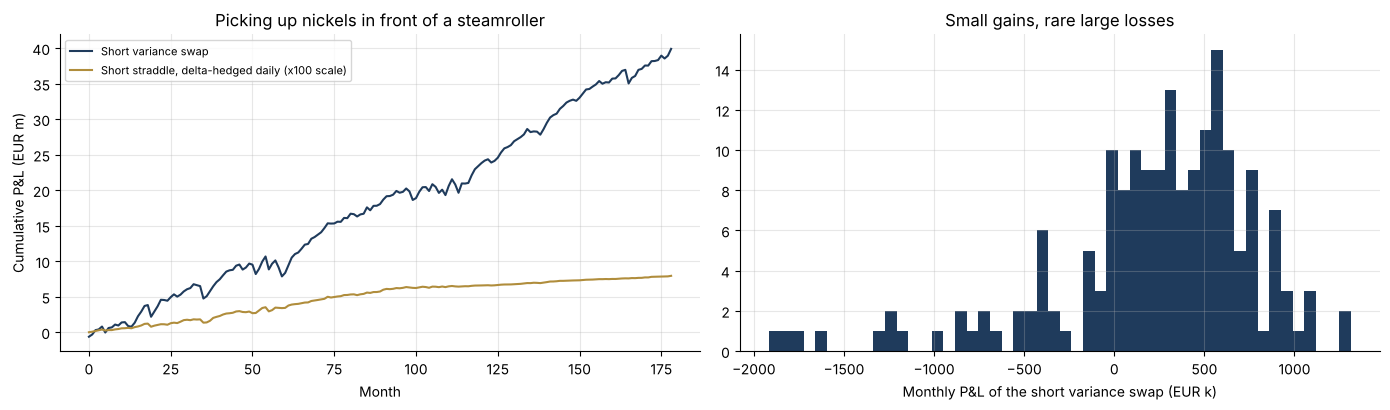

,Mean / month,Hit rate,Worst month,Skewness,Sharpe (ann.)
Short variance swap,"222,922",75%,"-1,917,572",-1.35,1.35
"Short straddle, delta-hedged daily",444,75%,"-5,825",-1.13,1.33


In [5]:
short_var = pd.DataFrame(short_variance_strategy(prices, implied, vega_notional=100_000))
straddle = pd.DataFrame(short_straddle_hedged(prices, implied, notional_contracts=1000))
strategies = {"Short variance swap": short_var["pnl"], "Short straddle, delta-hedged daily": straddle["pnl"]}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for (name, pnl), c in zip(strategies.items(), [NAVY, GOLD]):
    axes[0].plot(np.cumsum(pnl.values) / 1e6 * (100 if "straddle" in name else 1), color=c, lw=1.5,
                 label=name + (" (x100 scale)" if "straddle" in name else ""))
axes[0].set(xlabel="Month", ylabel="Cumulative P&L (EUR m)", title="Picking up nickels in front of a steamroller"); axes[0].legend(fontsize=8)
axes[1].hist(short_var["pnl"] / 1e3, bins=50, color=NAVY)
axes[1].set(xlabel="Monthly P&L of the short variance swap (EUR k)", title="Small gains, rare large losses")
plt.tight_layout(); plt.savefig("images/short_vol.png", dpi=150); plt.show()

def describe(p):
    return {"Mean / month": p.mean(), "Hit rate": (p > 0).mean(), "Worst month": p.min(), "Skewness": p.skew(),
            "Sharpe (ann.)": p.mean() / p.std() * np.sqrt(12)}
pd.DataFrame({k: describe(v) for k, v in strategies.items()}).T.style.format(
    {"Mean / month": "{:,.0f}", "Hit rate": "{:.0%}", "Worst month": "{:,.0f}", "Skewness": "{:.2f}", "Sharpe (ann.)": "{:.2f}"})

**Reading the result.** Selling volatility wins about three months out of four with a good
Sharpe ratio, and gives months of gains back in a single spike: a strongly negative
skewness. This is why single-stock variance swaps are usually capped (typically at 2.5 times
the strike) to limit the seller's tail. The delta-hedged straddle captures the same premium,
with an exposure that depends on where the spot is relative to the strike.

## Conclusions
- Variance swaps are priced off the whole smile, which is why their strike is above ATM vol in equities.
- The volatility risk premium is real but it is an insurance premium: its returns are
  negatively skewed, and the sizing should be done on the stress loss, not on the Sharpe ratio.
- **Next steps:** VIX futures and the term structure of volatility, corridor and gamma swaps,
  and dispersion trading (project 33).